In [29]:
import torch 
import torch.nn as nn

In [30]:
input =  torch.tensor([[0.7, 0.6]])

weights = torch.tensor([[0.9,0.4],
                        [-0.3,0.6],
                        [0.5,-0.5]])

biases = torch.tensor([0.2,-0.1,0.0])

# Linear Combinartion -> wX + b
raw_output = torch.matmul(input, weights.T ) + biases
raw_output

tensor([[1.0700, 0.0500, 0.0500]])

In [31]:
# Using in built functiion same ops as above

pytorch_layer = nn.Linear(in_features=2,out_features=3)

pytorch_layer.weight.data = weights
pytorch_layer.bias.data = biases

output = pytorch_layer(input)
output

tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<AddmmBackward0>)

In [32]:
# Activation Function
z = output
# 1. sigmoid 
sigmoid_output = torch.sigmoid(output)

# 2. Tanh
tanh_output = torch.tanh(z)

# 3. Relu
relu_output = torch.relu(z)
  

In [33]:
print(sigmoid_output)
print(tanh_output)
print(relu_output)

tensor([[0.7446, 0.5125, 0.5125]], grad_fn=<SigmoidBackward0>)
tensor([[0.7895, 0.0500, 0.0500]], grad_fn=<TanhBackward0>)
tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<ReluBackward0>)


In [34]:
# Custom Pytorch Neural Network Model 
# 2 inputs
# 16 Perceptron


class NNModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Layer 1 
        self.layer1 = nn.Linear(in_features=2,out_features=16)

        # Layer 2
        self.layer2 = nn.Linear(in_features=16,out_features=4)

        # Layer 3
        self.layer3 = nn.Linear(in_features=4,out_features=1)

        


    def forward(self, x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # Step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # Step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.relu(x)

        # Step 5 : Layer 3 Linear Comb
        x = self.layer3(x)

        # Step 6 : Layer 3 Activation Function
        x = torch.relu(x)



        return output



model = NNModel()

data = torch.randn(2,2)

predictions = model(data)


print(data)
print(predictions)


tensor([[ 0.4567, -1.2222],
        [-1.2357, -3.2577]])
tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<AddmmBackward0>)


In [35]:
# Backward Propagation

import torch
import torch.nn as nn
import torch.optim as optim

# Input
X = torch.tensor([[0.0,0.0],
                  [0.0,1.0],
                  [1.0,0.0],
                  [1.0,1.0]])
# Actual Output
y_act = torch.tensor([[0.0],
                      [1.0],
                      [1.0],
                      [0.0]])

# Define the neural network
class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        # Layer 1
        self.layer1 = nn.Linear(2,4)

        # Layer 2
        self.layer2 = nn.Linear(4,1)

    def forward(self,x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.sigmoid(x)

        return x


model = NNModel()

# Loss Function
# MSE is used for regression problems
# Classification problems -> Binary Cross Entropy Loss Function

criterion = nn.BCELoss()

optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent 

epochs = 7000

for epoch in range(epochs):

    predictions = model(X)

    loss = criterion(predictions, y_act)

    optimizer.zero_grad() # Gradients/Slope/Differentiation is being calcuated in every step # We need to reset the calculation for each new step

    loss.backward() # Calculate new gradients/slope

    optimizer.step() # Update the weights, take a step

    print(f'Epoch [{epoch + 1}/{epoch}], Loss: {loss.item():.4f}')

print(f'Loss: {loss.item():.4f}')

Epoch [1/0], Loss: 0.6912
Epoch [2/1], Loss: 0.6897
Epoch [3/2], Loss: 0.6882
Epoch [4/3], Loss: 0.6868
Epoch [5/4], Loss: 0.6855
Epoch [6/5], Loss: 0.6841
Epoch [7/6], Loss: 0.6828
Epoch [8/7], Loss: 0.6819
Epoch [9/8], Loss: 0.6807
Epoch [10/9], Loss: 0.6798
Epoch [11/10], Loss: 0.6787
Epoch [12/11], Loss: 0.6778
Epoch [13/12], Loss: 0.6768
Epoch [14/13], Loss: 0.6758
Epoch [15/14], Loss: 0.6750
Epoch [16/15], Loss: 0.6740
Epoch [17/16], Loss: 0.6733
Epoch [18/17], Loss: 0.6723
Epoch [19/18], Loss: 0.6715
Epoch [20/19], Loss: 0.6707
Epoch [21/20], Loss: 0.6697
Epoch [22/21], Loss: 0.6692
Epoch [23/22], Loss: 0.6682
Epoch [24/23], Loss: 0.6674
Epoch [25/24], Loss: 0.6668
Epoch [26/25], Loss: 0.6658
Epoch [27/26], Loss: 0.6652
Epoch [28/27], Loss: 0.6645
Epoch [29/28], Loss: 0.6636
Epoch [30/29], Loss: 0.6630
Epoch [31/30], Loss: 0.6622
Epoch [32/31], Loss: 0.6613
Epoch [33/32], Loss: 0.6608
Epoch [34/33], Loss: 0.6600
Epoch [35/34], Loss: 0.6591
Epoch [36/35], Loss: 0.6586
Epoch [37/3

In [59]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1000 Random coordinatea b/w -1 and 1
X = (torch.rand(1000, 2) * 2 ) - 1

# Label 1 if inside a radicious of 0.7, label 0 if outside

radicious_squared = 0.7 ** 2
y_act = (X[:,0]**2 + X[:,1]**2 < radicious_squared).float().view(-1,1)

print(X.shape)


torch.Size([1000, 2])


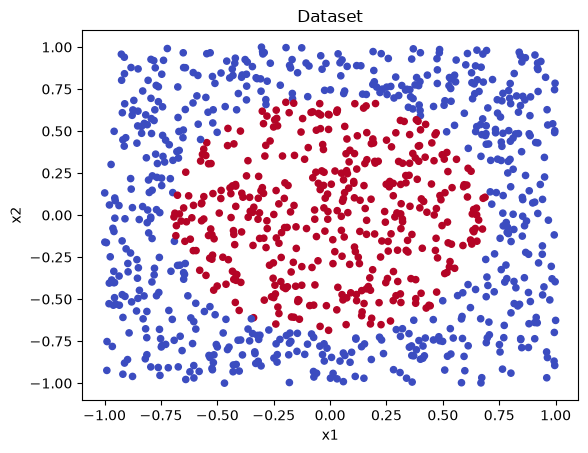

In [60]:
import matplotlib.pyplot as plt 
plt.scatter(X[:,0], X[:,1], c = y_act.squeeze(), cmap='coolwarm', s =20)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title('Dataset')
plt.show()

In [61]:
# Define the neural network
class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        # Layer 1
        self.layer1 = nn.Linear(2,30)

        # Layer 2
        self.layer2 = nn.Linear(30, 1)

   


    def forward(self,x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.sigmoid(x)

        

        return x

In [ ]:
model = NNModel()

# Loss Function
# MSE is used for regression problems
# Classification problems -> Binary Cross Entropy Loss Function

criterion = nn.BCELoss()

optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent 

epochs = 10000

for epoch in range(epochs):

    predictions = model(X)

    loss = criterion(predictions, y_act)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()
    
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10000x1 and 2x30)

In [ ]:
model.eval()

with torch.no_grad():
    probabilities = torch.sigmoid(model(X))
    predicted_labels = (probabilities >= 0.5).float()

    accuracy = (predicted_labels == y_act).float().mean()

    print(f"Training accuracy: {accuracy.item():.4%}")
    

Training accuracy: 37.6000%


In [41]:
for name, parameter in model.named_parameters():
    print(
        name,
        parameter.grad.norm().item()
        if parameter.grad is not None else None
    )

print(model)

layer1.weight 0.0032885607797652483
layer1.bias 0.001881877426058054
layer2.weight 0.0036022476851940155
layer2.bias 0.00028791208751499653
NNModel(
  (layer1): Linear(in_features=2, out_features=30, bias=True)
  (layer2): Linear(in_features=30, out_features=1, bias=True)
)


Overfitting in NN

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import math

# Dataset
torch.manual_seed(42)

def generate_data(num_points):

    X = (torch.rand(num_points, 1) * 8) - 4

    noise = torch.rand(num_points, 1) * 0.3

    y = torch.sin(X) + noise
    return X, y

In [51]:
# Training set : Here I am deliberatrly trying to overfit for demonstration
X_train, y_train = generate_data(30000)

X_val, y_val = generate_data(10000)

class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,1)
        )
        # weghts = 128 + 128 * 128 + 128, Biases = 128 + 128 + 1

    def forward(self, x):
        return self.net(x)


model = NNModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= 0.01)

In [52]:
writer = SummaryWriter('runs//demo')


In [53]:
epochs = 800

for epoch in range(epochs):             

    #---------------Training Phase------------------------
    model.train()
    #Forward Pass
    train_preds = model(X_train)

    #Loss calculation
    train_loss = criterion(train_preds, y_train)

    # Backward pass
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    #------------Validation Phase------------------
    model.eval() # set to evaluation mode

    with torch.no_grad():
        val_preds = model(X_val)
        val_loss = criterion(val_preds,y_val)


    # -----------Logging to Graphs----------------
    # We Group them under the name 'Loss' so they appear on the same graph
    writer.add_scalars('Loss',{
        'Train': train_loss.item(),
        'Validation': val_loss.item()
    }, epoch)

writer.close()
print(f"Final Train Loss:{train_loss.item():.4f}")
print(f"Final validation  Loss:{val_loss.item():.4f}")

Final Train Loss:0.0076
Final validation  Loss:0.0076


In [54]:
!tensorboard --logdir=runs

TensorFlow installation not found - running with reduced feature set.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.21.0 at http://localhost:6006/ (Press CTRL+C to quit)
^C


Early Stopping

In [63]:
import torch 
import numpy as np

class EarlyStopper:
    def __init__(self,patience=5,min_delta=0.001):

        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = np.inf
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):

        if val_loss < self.best_loss - self.min_delta:
            self.counter = 0
            self.best_loss = val_loss

        else:
            self.counter = self.counter + 1
            print(f'Early Stopping Counter : {self.counter} out of {self.patience}')

            if self.counter > self.patience:
                self.early_stop = True

In [64]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import math

# Dataset
torch.manual_seed(42)

def generate_data(num_points):

    X = (torch.rand(num_points, 1) * 8) - 4

    noise = torch.rand(num_points, 1) * 0.3

    y = torch.sin(X) + noise
    return X, y

In [65]:
# Training set : Here I am deliberatrly trying to overfit for demonstration
X_train, y_train = generate_data(30000)

X_val, y_val = generate_data(10000)

class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,1)
        )
        # weghts = 128 + 128 * 128 + 128, Biases = 128 + 128 + 1

    def forward(self, x):
        return self.net(x)


model = NNModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= 0.01)